# Predicting Personal Loan Default — Initial Report and EDA

**Capstone, Module 20: data cleaning, exploratory data analysis and a baseline model**

**Research question:** Can we predict whether a borrower will default on a personal loan using only the information available when the loan is approved?

**Contents**
1. [Business understanding](#1.-Business-understanding)
2. [Data understanding](#2.-Data-understanding)
3. [Data cleaning](#3.-Data-cleaning)
4. [Feature engineering](#4.-Feature-engineering)
5. [Outlier analysis](#5.-Outlier-analysis)
6. [Exploratory data analysis](#6.-Exploratory-data-analysis)
7. [Baseline model](#7.-Baseline-model)
8. [Summary of findings and next steps](#8.-Summary-of-findings-and-next-steps)

## 1. Business understanding

When a borrower stops paying a loan, the lender loses the money still owed. Lenders set interest rates to cover these losses, so defaults make borrowing more expensive for everyone. If a lender could spot higher-risk applications **before** approving them, it could review them more carefully, adjust the rate or amount, or ask for more information.

**Data problem:** a binary classification task. The target is whether a loan was **charged off** (defaulted, 1) or **fully paid** (0). Only information available when the loan was issued may be used as input; anything recorded later (payments, recoveries) would leak the answer.

In [1]:
# Data handling and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Modeling
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, recall_score, precision_score, accuracy_score,
                             RocCurveDisplay, ConfusionMatrixDisplay)

import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)
RANDOM_STATE = 42

## 2. Data understanding

The data is LendingClub's public loan file for loans issued **2007–2011**: one row per loan, with borrower details, loan terms, and the final loan status. (LendingClub is a US peer-to-peer lending platform.)

In [2]:
loans_raw = pd.read_csv('../data/lending_club_loans_2007_2011.csv', low_memory=False)
print(f'Rows: {loans_raw.shape[0]:,}   Columns: {loans_raw.shape[1]}')
loans_raw.iloc[:3, :12]

Rows: 39,717   Columns: 111


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length
0,1077501,1296599,5000,5000,4975.0,36 months,10.65%,162.87,B,B2,NaN,10+ years
1,1077430,1314167,2500,2500,2500.0,60 months,15.27%,59.83,C,C4,Ryder,< 1 year
2,1077175,1313524,2400,2400,2400.0,36 months,15.96%,84.33,C,C5,NaN,10+ years


In [3]:
# Loan outcomes in the raw data
loans_raw['loan_status'].value_counts()

loan_status
Fully Paid     32950
Charged Off     5627
Current         1140
Name: count, dtype: int64

In [4]:
# How complete is each column?
missing_share = loans_raw.isnull().mean()
print(f'Columns that are completely empty:   {(missing_share == 1).sum()}')
print(f'Columns more than 50% empty:         {((missing_share > 0.5) & (missing_share < 1)).sum()}')
print(f'Columns with a single value:         {(loans_raw.nunique() == 1).sum()}')
print(f'Duplicate rows: {loans_raw.duplicated().sum()}   Duplicate loan ids: {loans_raw["id"].duplicated().sum()}')

Columns that are completely empty:   54
Columns more than 50% empty:         3


Columns with a single value:         9


Duplicate rows: 0   Duplicate loan ids: 0


**First observations**
- 39,717 loans and 111 columns, but **54 columns are completely empty** and 3 more are over half empty.
- Several columns hold a single value for every loan and carry no information.
- About 1,140 loans were still **Current** (not finished) when the data was collected, so their outcome is unknown.
- Many columns describe what happened **after** the loan was issued (amount repaid, recoveries, last payment date). These must be removed, otherwise the model would be "told" the answer.
- Some numeric fields are stored as text: `int_rate` ("10.99%"), `revol_util`, `term` (" 36 months"), `emp_length` ("10+ years") and the dates.

## 3. Data cleaning

Steps, each explained in the code comments:
1. Keep only finished loans (Fully Paid or Charged Off) and create the target.
2. Remove empty, constant, identifier, free-text and post-issue (leakage) columns.
3. Check for duplicates.
4. Convert text fields to numbers and dates.
5. Handle the remaining missing values.

In [5]:
# 1. Keep finished loans only; 'Current' loans have no final outcome yet
loans = loans_raw[loans_raw['loan_status'].isin(['Fully Paid', 'Charged Off'])].copy()
loans['default'] = (loans['loan_status'] == 'Charged Off').astype(int)

# 2. Keep only information known when the loan was issued
columns_to_keep = [
    # loan terms
    'loan_amnt', 'term', 'int_rate', 'installment', 'grade', 'purpose', 'issue_d',
    # borrower profile
    'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'addr_state',
    # credit history
    'dti', 'delinq_2yrs', 'earliest_cr_line', 'inq_last_6mths', 'open_acc', 'pub_rec',
    'revol_bal', 'revol_util', 'total_acc', 'pub_rec_bankruptcies',
    # target
    'default']
loans = loans[columns_to_keep]

# 3. Duplicates
print(f'Duplicate rows after selection: {loans.duplicated().sum()}')
print(f'Finished loans kept: {len(loans):,}   Columns kept: {loans.shape[1]}')

Duplicate rows after selection: 0
Finished loans kept: 38,577   Columns kept: 23


**Why these columns were removed:** identifiers and URLs (`id`, `member_id`, `url`), free-text fields with thousands of unique values (`desc`, `emp_title`, `title`), `zip_code` (partly masked), `sub_grade` (a finer version of `grade`, which also drives `int_rate`), the funded amounts (decided by investors after the application), single-value columns, and every payment/recovery column recorded after the loan started.

In [6]:
# 4. Convert text fields to proper types
loans['term_months'] = loans['term'].str.extract(r'(\d+)').astype(int)
loans['int_rate'] = loans['int_rate'].str.rstrip('%').astype(float)
loans['revol_util'] = loans['revol_util'].str.rstrip('%').astype(float)

# '< 1 year' -> 0, '10+ years' -> 10, others -> the number of years
loans['emp_years'] = (loans['emp_length']
                      .replace({'< 1 year': '0', '10+ years': '10'})
                      .str.extract(r'(\d+)')[0].astype(float))

loans['issue_date'] = pd.to_datetime(loans['issue_d'], format='%b-%y')
cr_line = pd.to_datetime(loans['earliest_cr_line'], format='%b-%y')
# Two-digit years like '62' are read as 2062; move anything after the issue date back 100 years
cr_line = cr_line.where(cr_line <= loans['issue_date'], cr_line - pd.DateOffset(years=100))
loans['earliest_credit_date'] = cr_line

loans = loans.drop(columns=['term', 'emp_length', 'issue_d', 'earliest_cr_line'])
loans.dtypes.value_counts()

int64             9
float64           7
str               5
datetime64[us]    2
Name: count, dtype: int64

In [7]:
# 5. Remaining missing values
remaining = loans.isnull().sum()
remaining[remaining > 0].to_frame('missing').assign(pct=lambda d: (d['missing'] / len(loans) * 100).round(2))

,missing,pct
revol_util,50,0.13
pub_rec_bankruptcies,697,1.81
emp_years,1033,2.68


In [8]:
# Missing employment length: keep a flag (missing could itself be informative), fill with the median
loans['emp_length_missing'] = loans['emp_years'].isnull().astype(int)
loans['emp_years'] = loans['emp_years'].fillna(loans['emp_years'].median())

# Revolving utilisation: tiny number missing -> median
loans['revol_util'] = loans['revol_util'].fillna(loans['revol_util'].median())

# Bankruptcies: missing almost always means none on record -> 0
loans['pub_rec_bankruptcies'] = loans['pub_rec_bankruptcies'].fillna(0)

# 'OTHER'/'NONE' home ownership are tiny groups -> combine
loans['home_ownership'] = loans['home_ownership'].replace({'NONE': 'OTHER'})

print(f'Missing values left: {loans.isnull().sum().sum()}')

Missing values left: 0


## 4. Feature engineering

New features that describe affordability and credit experience better than the raw columns:
- **`credit_history_years`**: years between the first credit line and the loan date.
- **`loan_to_income`**: loan amount as a share of annual income.
- **`payment_to_income`**: monthly instalment as a share of monthly income.
- **`issue_year`**: to check whether default rates changed over time.
- **`has_derogatory`**: any public record, bankruptcy or recent delinquency.

In [9]:
loans['credit_history_years'] = ((loans['issue_date'] - loans['earliest_credit_date']).dt.days / 365.25).round(1)
loans['loan_to_income'] = loans['loan_amnt'] / loans['annual_inc']
loans['payment_to_income'] = loans['installment'] / (loans['annual_inc'] / 12)
loans['issue_year'] = loans['issue_date'].dt.year
loans['has_derogatory'] = ((loans['pub_rec'] > 0) | (loans['pub_rec_bankruptcies'] > 0)
                           | (loans['delinq_2yrs'] > 0)).astype(int)

loans = loans.drop(columns=['issue_date', 'earliest_credit_date'])
loans[['credit_history_years', 'loan_to_income', 'payment_to_income', 'issue_year', 'has_derogatory']].describe().round(2)

,credit_history_years,loan_to_income,payment_to_income,issue_year,has_derogatory
count,38577.00,38577.00,38577.00,38577.00,38577.00
mean,13.72,0.19,0.07,2010.31,0.16
std,6.83,0.12,0.04,0.88,0.36
min,3.00,0.00,0.00,2007.00,0.00
25%,9.10,0.10,0.04,2010.00,0.00
50%,12.50,0.16,0.06,2011.00,0.00
75%,17.00,0.25,0.09,2011.00,0.00
max,65.40,0.83,0.32,2011.00,1.00


## 5. Outlier analysis

The IQR rule (values beyond 1.5 × IQR from the quartiles) is used to flag unusual values in the main continuous features.

In [10]:
continuous = ['loan_amnt', 'int_rate', 'annual_inc', 'dti', 'revol_bal', 'revol_util',
              'credit_history_years', 'loan_to_income', 'payment_to_income']

def iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)).sum()

outlier_summary = pd.DataFrame({
    'outliers': {c: iqr_outliers(loans[c]) for c in continuous},
    'max': loans[continuous].max().round(2),
    '99th pct': loans[continuous].quantile(0.99).round(2)})
outlier_summary['pct'] = (outlier_summary['outliers'] / len(loans) * 100).round(1)
outlier_summary

,outliers,max,99th pct,pct
loan_amnt,1088,35000.00,35000.00,2.8
int_rate,65,24.40,20.99,0.2
annual_inc,1762,6000000.00,234144.00,4.6
dti,0,29.99,26.53,0.0
revol_bal,2423,149588.00,83276.72,6.3
revol_util,0,99.90,98.50,0.0
credit_history_years,1333,65.40,35.92,3.5
loan_to_income,847,0.83,0.52,2.2
payment_to_income,732,0.32,0.19,1.9


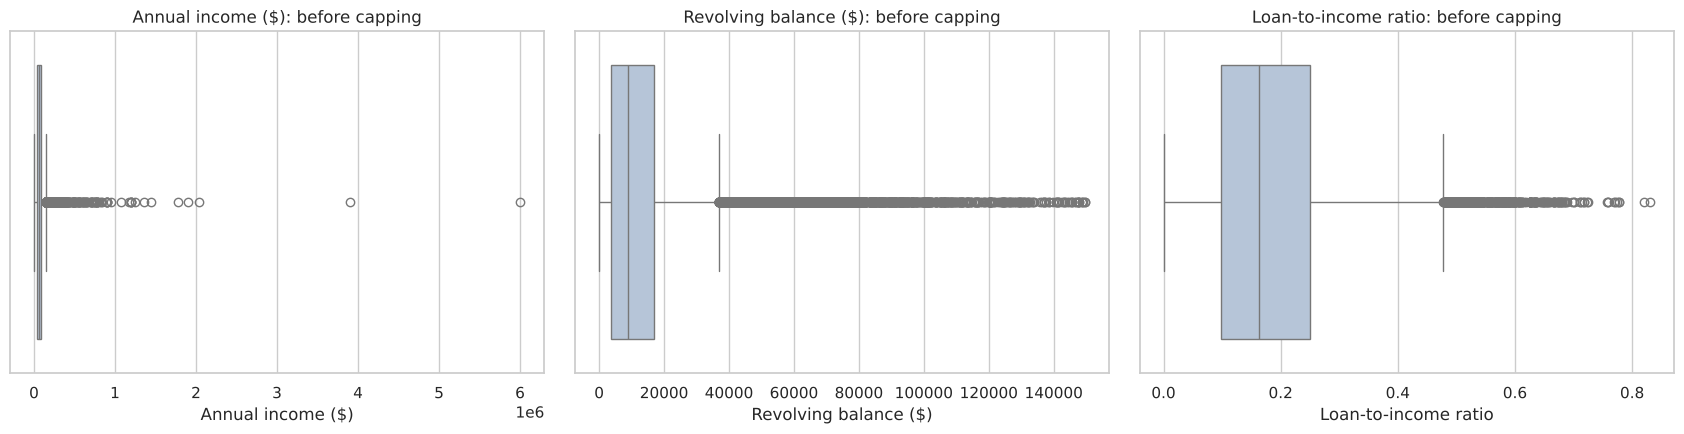

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col, label in zip(axes, ['annual_inc', 'revol_bal', 'loan_to_income'],
                          ['Annual income ($)', 'Revolving balance ($)', 'Loan-to-income ratio']):
    sns.boxplot(x=loans[col], ax=ax, color='lightsteelblue')
    ax.set_title(f'{label}: before capping')
    ax.set_xlabel(label)
plt.tight_layout()
plt.savefig('../images/outliers_before.png', dpi=100)
plt.show()

Income, revolving balance and the ratios are strongly right-skewed: a few borrowers report incomes up to \$6 million. These look like genuine (if rare) high earners rather than errors, so instead of deleting the loans, the extreme values are **capped at the 99th percentile** (winsorizing). This keeps every loan while stopping a handful of values from dominating the model. Interest rate, DTI and utilisation have few or no outliers and are left as they are.

In [12]:
cap_columns = ['annual_inc', 'revol_bal', 'loan_to_income', 'payment_to_income']
for col in cap_columns:
    loans[col] = loans[col].clip(upper=loans[col].quantile(0.99))

loans['log_annual_inc'] = np.log(loans['annual_inc'])
print(f"Annual income after capping: max ${loans['annual_inc'].max():,.0f}")

Annual income after capping: max $234,144


## 6. Exploratory data analysis

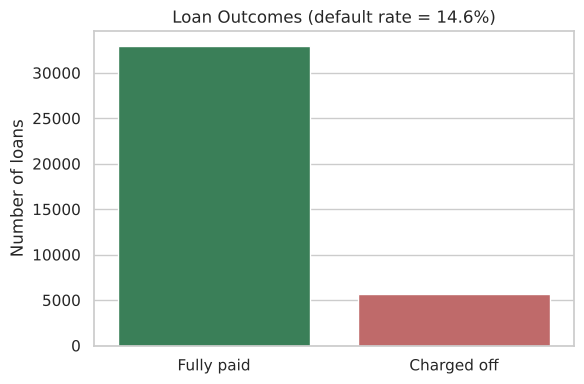

In [13]:
default_rate = loans['default'].mean()
fig, ax = plt.subplots(figsize=(6, 4))
counts = loans['default'].map({0: 'Fully paid', 1: 'Charged off'}).value_counts()
sns.barplot(x=counts.index, y=counts.values, palette=['seagreen', 'indianred'], ax=ax)
ax.set_title(f'Loan Outcomes (default rate = {default_rate:.1%})')
ax.set_xlabel('')
ax.set_ylabel('Number of loans')
plt.tight_layout()
plt.savefig('../images/target_balance.png', dpi=100)
plt.show()

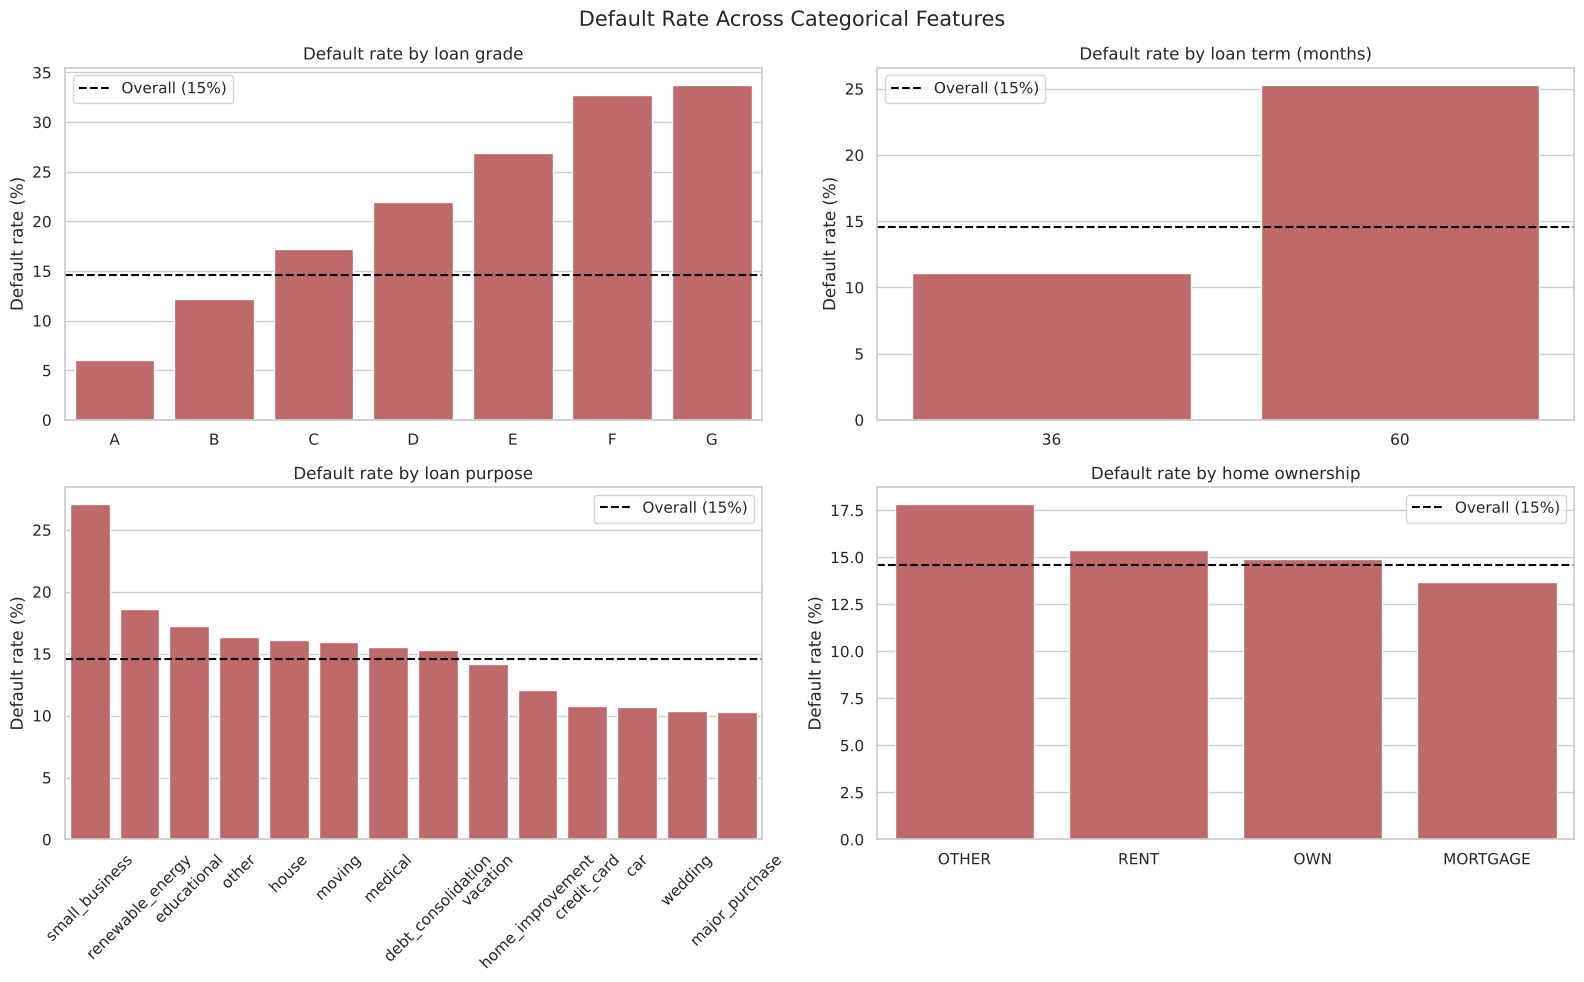

In [14]:
def plot_default_rate(column, ax, order=None, title=None, rotate=0, legend_loc='upper right'):
    """Bar chart of default rate (%) for each value of a categorical column."""
    rates = loans.groupby(column)['default'].mean().mul(100)
    rates = rates.reindex(order) if order is not None else rates.sort_values(ascending=False)
    sns.barplot(x=rates.index.astype(str), y=rates.values, color='indianred', ax=ax)
    ax.axhline(default_rate * 100, color='black', linestyle='--', label=f'Overall ({default_rate:.0%})')
    ax.set_title(title)
    ax.set_xlabel('')
    ax.set_ylabel('Default rate (%)')
    ax.tick_params(axis='x', rotation=rotate)
    ax.legend(loc=legend_loc)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
plot_default_rate('grade', axes[0, 0], order=list('ABCDEFG'), title='Default rate by loan grade', legend_loc='upper left')
plot_default_rate('term_months', axes[0, 1], order=[36, 60], title='Default rate by loan term (months)', legend_loc='upper left')
plot_default_rate('purpose', axes[1, 0], title='Default rate by loan purpose', rotate=45)
plot_default_rate('home_ownership', axes[1, 1], title='Default rate by home ownership')
fig.suptitle('Default Rate Across Categorical Features', fontsize=15)
plt.tight_layout()
plt.savefig('../images/default_rate_by_category.png', dpi=100)
plt.show()

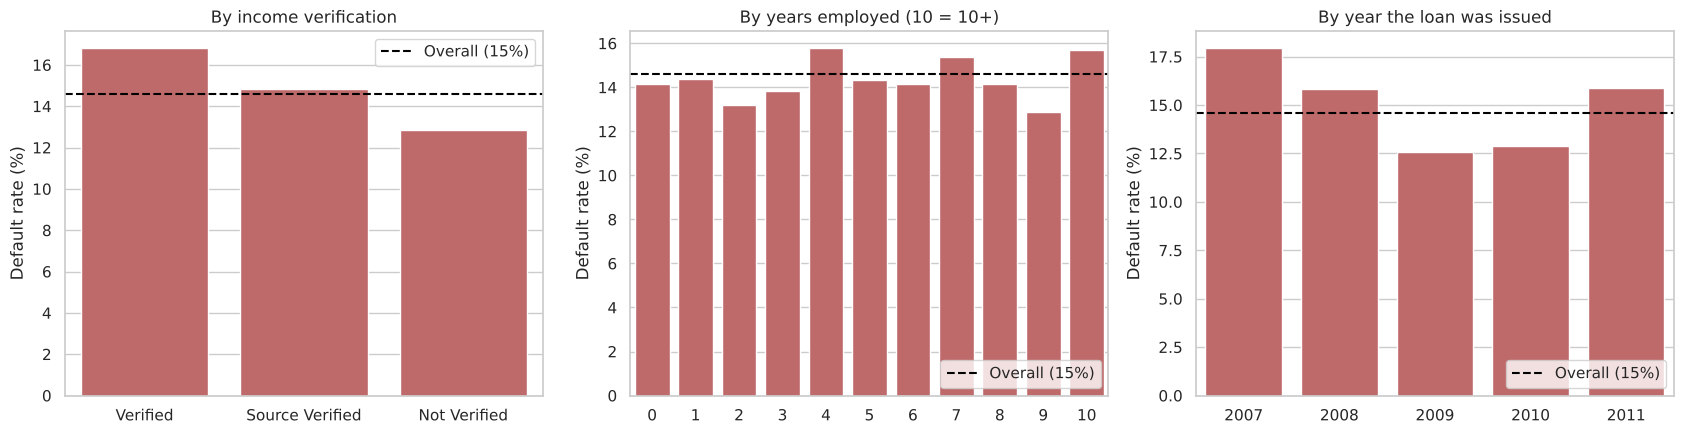

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
plot_default_rate('verification_status', axes[0], title='By income verification')
plot_default_rate('emp_years', axes[1], order=sorted(loans['emp_years'].unique()), title='By years employed (10 = 10+)', legend_loc='lower right')
axes[1].set_xticklabels([str(int(float(t.get_text()))) for t in axes[1].get_xticklabels()])
plot_default_rate('issue_year', axes[2], order=sorted(loans['issue_year'].unique()), title='By year the loan was issued', legend_loc='lower right')
plt.tight_layout()
plt.savefig('../images/default_rate_other.png', dpi=100)
plt.show()

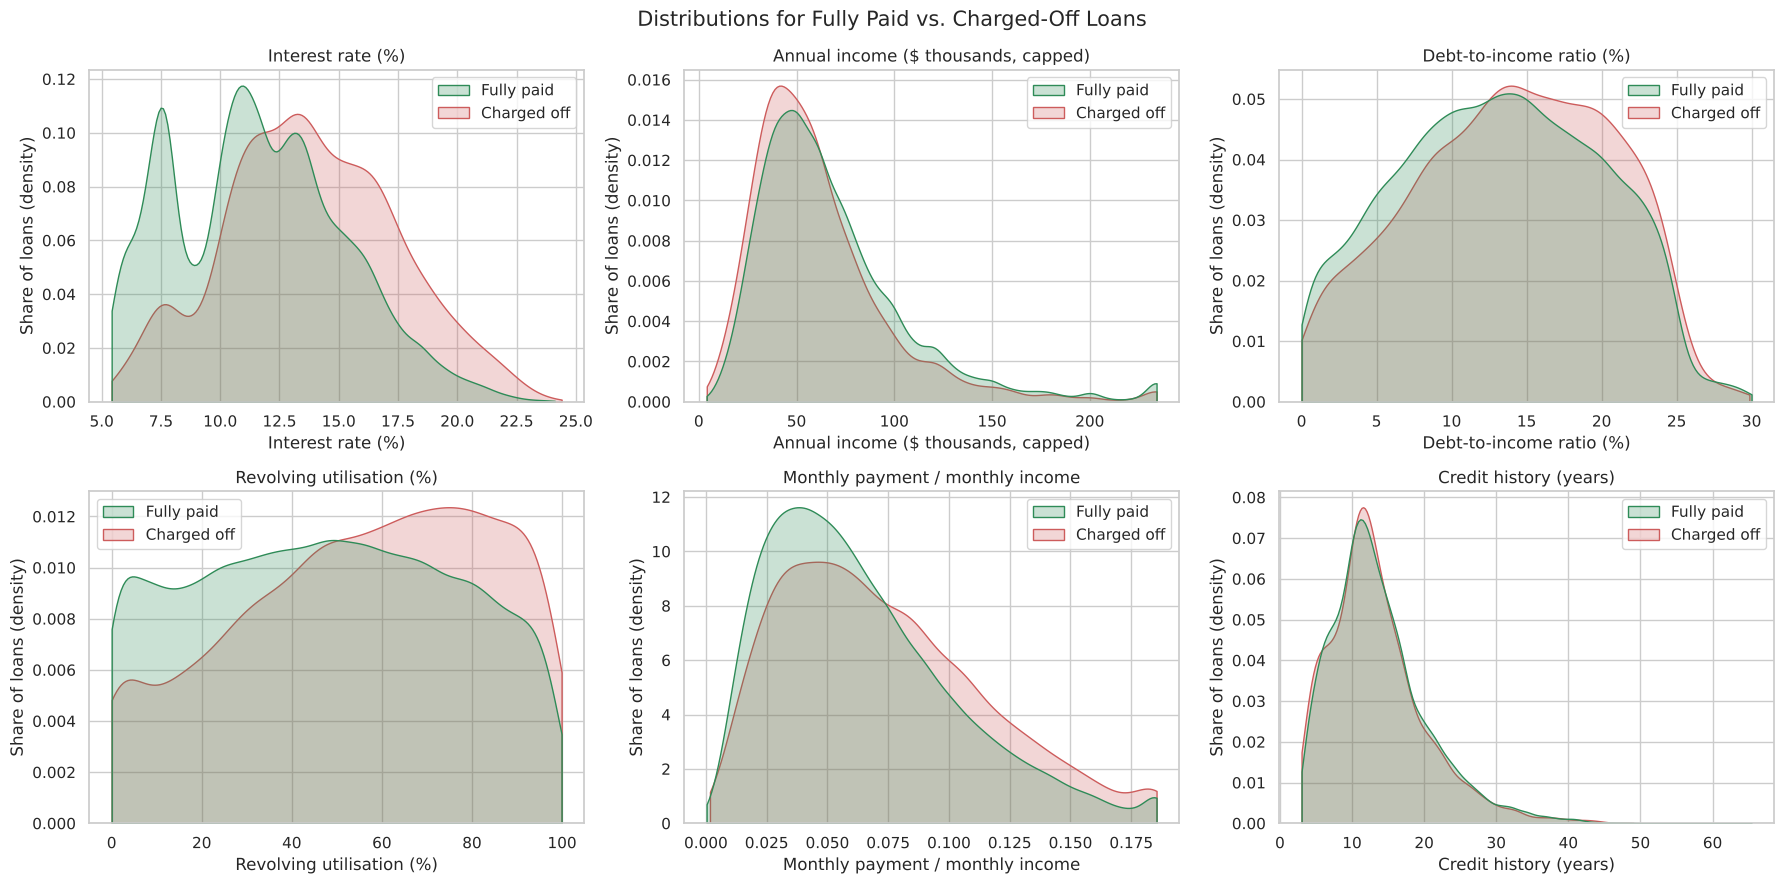

In [16]:
# Continuous features: distribution for paid vs defaulted loans
plot_df = loans.assign(outcome=loans['default'].map({0: 'Fully paid', 1: 'Charged off'}),
                       annual_inc_k=loans['annual_inc'] / 1000)
plot_cols = {'int_rate': 'Interest rate (%)', 'annual_inc_k': 'Annual income ($ thousands, capped)',
             'dti': 'Debt-to-income ratio (%)', 'revol_util': 'Revolving utilisation (%)',
             'payment_to_income': 'Monthly payment / monthly income', 'credit_history_years': 'Credit history (years)'}
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, (col, label) in zip(axes.flat, plot_cols.items()):
    sns.kdeplot(data=plot_df, x=col, hue='outcome', hue_order=['Fully paid', 'Charged off'],
                common_norm=False, fill=True, cut=0, palette=['seagreen', 'indianred'], ax=ax)
    ax.set_title(label)
    ax.set_xlabel(label)
    ax.set_ylabel('Share of loans (density)')
    ax.get_legend().set_title('')
fig.suptitle('Distributions for Fully Paid vs. Charged-Off Loans', fontsize=15)
plt.tight_layout()
plt.savefig('../images/continuous_by_outcome.png', dpi=100)
plt.show()

In [17]:
# Median of each continuous feature by outcome
loans.groupby('default')[['int_rate', 'annual_inc', 'dti', 'revol_util', 'payment_to_income', 'credit_history_years', 'loan_amnt', 'loan_to_income']].median().round(2).rename(index={0: 'Fully paid', 1: 'Charged off'})

,int_rate,annual_inc,dti,revol_util,payment_to_income,credit_history_years,loan_amnt,loan_to_income
default,,,,,,,,
Fully paid,11.49,60000.0,13.20,47.6,0.06,12.5,9600.0,0.16
Charged off,13.61,53000.0,14.29,58.2,0.07,12.3,10000.0,0.20


In [18]:
# Default rate across interest-rate bands (inferential check of the trend)
loans['rate_band'] = pd.qcut(loans['int_rate'], 5, labels=['Lowest 20%', '2nd', '3rd', '4th', 'Highest 20%'])
loans.groupby('rate_band', observed=True).agg(min_rate=('int_rate', 'min'), max_rate=('int_rate', 'max'),
                                              loans=('default', 'size'), default_rate=('default', 'mean')).round(3)

,min_rate,max_rate,loans,default_rate
rate_band,,,,
Lowest 20%,5.42,7.90,8013,0.054
2nd,7.91,10.99,8311,0.103
3rd,11.03,12.84,6939,0.147
4th,12.86,15.21,7639,0.172
Highest 20%,15.23,24.40,7675,0.262


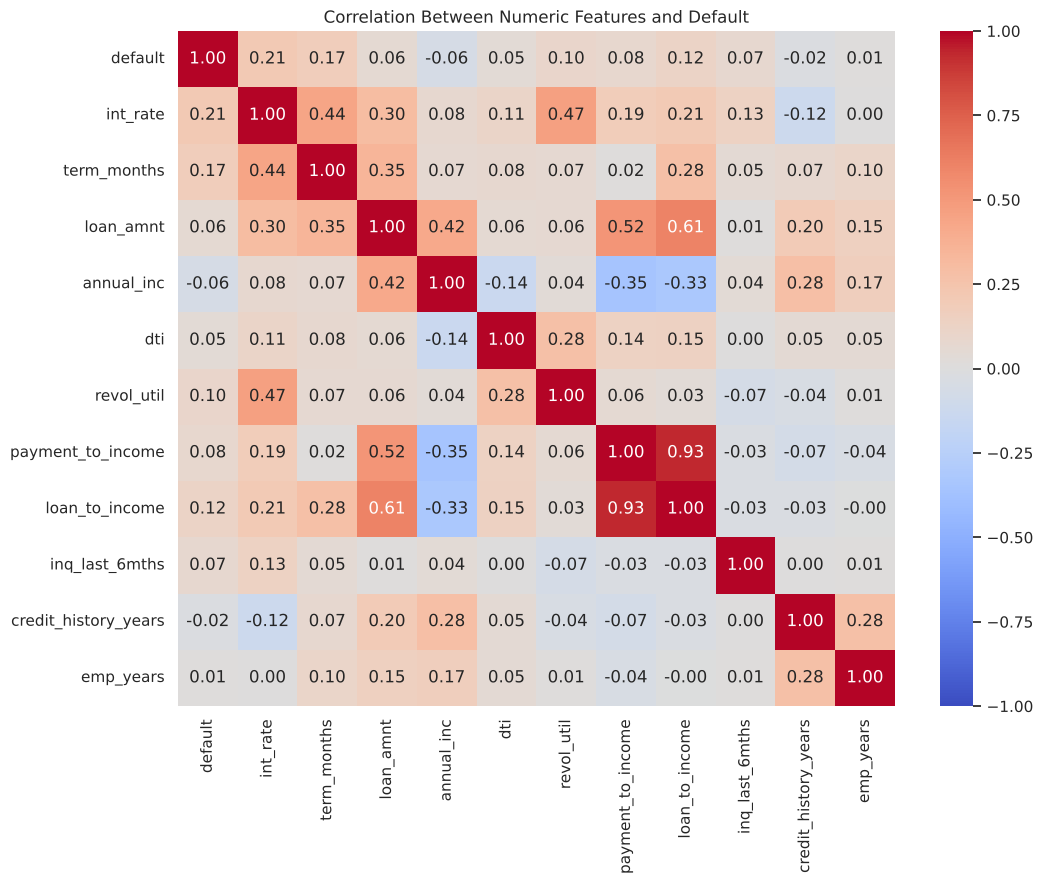

In [19]:
corr_cols = ['default', 'int_rate', 'term_months', 'loan_amnt', 'annual_inc', 'dti', 'revol_util',
             'payment_to_income', 'loan_to_income', 'inq_last_6mths', 'credit_history_years', 'emp_years']
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(loans[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
ax.set_title('Correlation Between Numeric Features and Default')
plt.tight_layout()
plt.savefig('../images/correlation_heatmap.png', dpi=100)
plt.show()

**What the EDA shows**
- **About 1 in 7 loans (14.6%) defaults**, so the classes are imbalanced.
- **Loan grade and interest rate are the clearest signals.** Default rises steadily from 6% for grade A to 34% for grade G. By interest rate, the cheapest 20% of loans default 5% of the time and the most expensive 20% default 26% of the time. Defaulted loans had a median rate of 13.6%, against 11.5% for repaid loans.
- **60-month loans default more than twice as often** as 36-month loans (25% vs 11%).
- **Small business loans are the riskiest purpose** at 27%. Car, credit card, wedding and major purchase loans are the safest at around 10–11%.
- **Affordability matters.** Borrowers who defaulted had lower incomes (median \$53K vs \$60K) and borrowed more relative to income (loan-to-income 0.20 vs 0.16). Their credit lines were also more heavily used (revolving utilisation 58% vs 48%), and they had more recent credit inquiries.
- **Renters default slightly more than homeowners with a mortgage** (15.4% vs 13.7%).
- **Some features barely matter.** Years employed shows no clear pattern, and credit history length is almost identical for both groups.
- **One counter-intuitive pattern:** loans with *verified* income default more (16.8%) than unverified ones (12.8%). This is most likely because LendingClub chose to verify riskier or larger applications, not because verification causes default.
- Default rates also changed by year: they were highest in 2007 (18%) and lowest in 2009–2010 (13%).

## 7. Baseline model

**Model:** logistic regression — simple, fast and explainable (its coefficients show which features push risk up or down). Module 24 will compare more complex models against it.

**Evaluation metric:** **ROC-AUC** is the main metric. Only ~15% of loans default, so a model that approves everyone is 85% "accurate" while catching no defaults — accuracy is misleading here. ROC-AUC measures how well the model **ranks** borrowers from riskiest to safest (0.5 = random, 1.0 = perfect), which is what a lender needs to decide who gets a closer review. **Recall** (share of defaults caught) and **precision** (share of flagged loans that really default) are also reported, because missing a default usually costs a lender more than reviewing a safe loan.

The model uses `class_weight='balanced'` so that the rarer default class is not ignored, and is checked with 5-fold stratified cross-validation.

In [20]:
numeric_features = ['loan_amnt', 'int_rate', 'installment', 'term_months', 'log_annual_inc', 'dti',
                    'delinq_2yrs', 'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util',
                    'total_acc', 'pub_rec_bankruptcies', 'emp_years', 'emp_length_missing',
                    'credit_history_years', 'loan_to_income', 'payment_to_income', 'has_derogatory']
categorical_features = ['grade', 'home_ownership', 'verification_status', 'purpose']
# addr_state (50 states) and issue_year are left out of the baseline: the first adds many sparse
# columns, and the second would not generalise to future loans.

X = loans[numeric_features + categorical_features]
y = loans['default']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
print(f'Train: {len(X_train):,} loans   Test: {len(X_test):,} loans   Default rate: {y.mean():.3f}')

Train: 28,932 loans   Test: 9,645 loans   Default rate: 0.146


In [21]:
preprocessor = make_column_transformer(
    (OneHotEncoder(handle_unknown='ignore'), categorical_features),
    (StandardScaler(), numeric_features))

# Naive reference: always predict "fully paid"
naive = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
print(f'Naive model accuracy: {accuracy_score(y_test, naive.predict(X_test)):.3f}  (catches 0% of defaults)')

baseline = Pipeline([('preprocess', preprocessor),
                     ('model', LogisticRegression(max_iter=2000, class_weight='balanced'))])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_auc = cross_val_score(baseline, X_train, y_train, cv=cv, scoring='roc_auc')
print(f'5-fold CV ROC-AUC: {cv_auc.mean():.3f} (+/- {cv_auc.std():.3f})')

Naive model accuracy: 0.854  (catches 0% of defaults)


5-fold CV ROC-AUC: 0.709 (+/- 0.013)


In [22]:
baseline.fit(X_train, y_train)
test_prob = baseline.predict_proba(X_test)[:, 1]
test_pred = baseline.predict(X_test)

baseline_scores = pd.Series({
    'ROC-AUC': roc_auc_score(y_test, test_prob),
    'Recall (defaults caught)': recall_score(y_test, test_pred),
    'Precision (flagged loans that default)': precision_score(y_test, test_pred),
    'Accuracy': accuracy_score(y_test, test_pred)}).round(3)
baseline_scores.to_frame('Baseline logistic regression (test set)')

,Baseline logistic regression (test set)
ROC-AUC,0.713
Recall (defaults caught),0.641
Precision (flagged loans that default),0.248
Accuracy,0.664


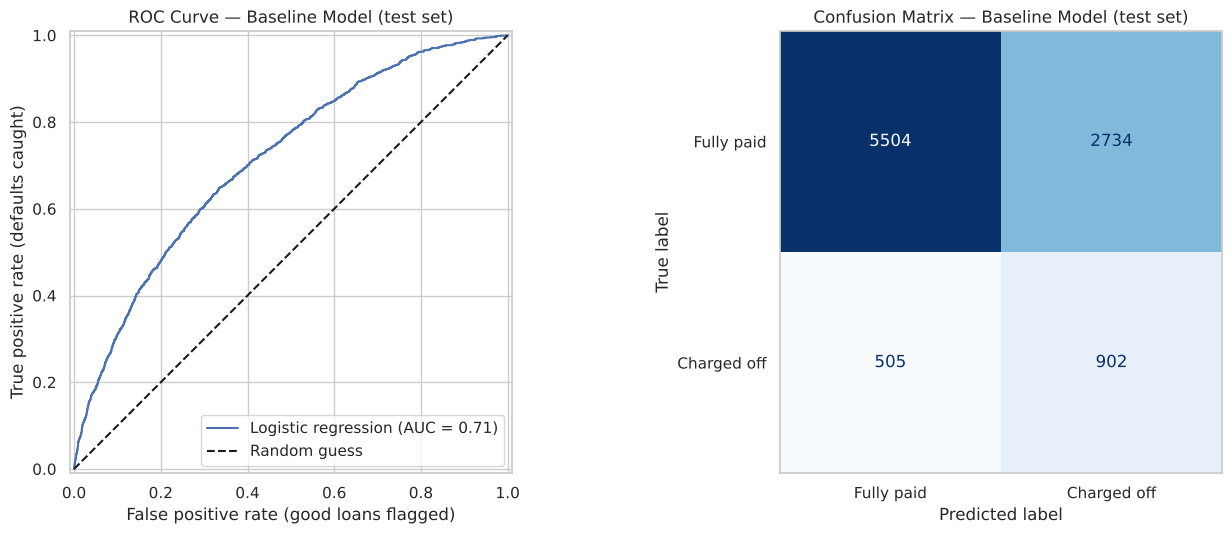

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
RocCurveDisplay.from_predictions(y_test, test_prob, name='Logistic regression', ax=axes[0])
axes[0].plot([0, 1], [0, 1], 'k--', label='Random guess')
axes[0].set_title('ROC Curve — Baseline Model (test set)')
axes[0].set_xlabel('False positive rate (good loans flagged)')
axes[0].set_ylabel('True positive rate (defaults caught)')
axes[0].legend(loc='lower right')

ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=['Fully paid', 'Charged off'],
                                        cmap='Blues', ax=axes[1], colorbar=False)
axes[1].set_title('Confusion Matrix — Baseline Model (test set)')
axes[1].grid(False)
plt.tight_layout()
plt.savefig('../images/baseline_model.png', dpi=100)
plt.show()

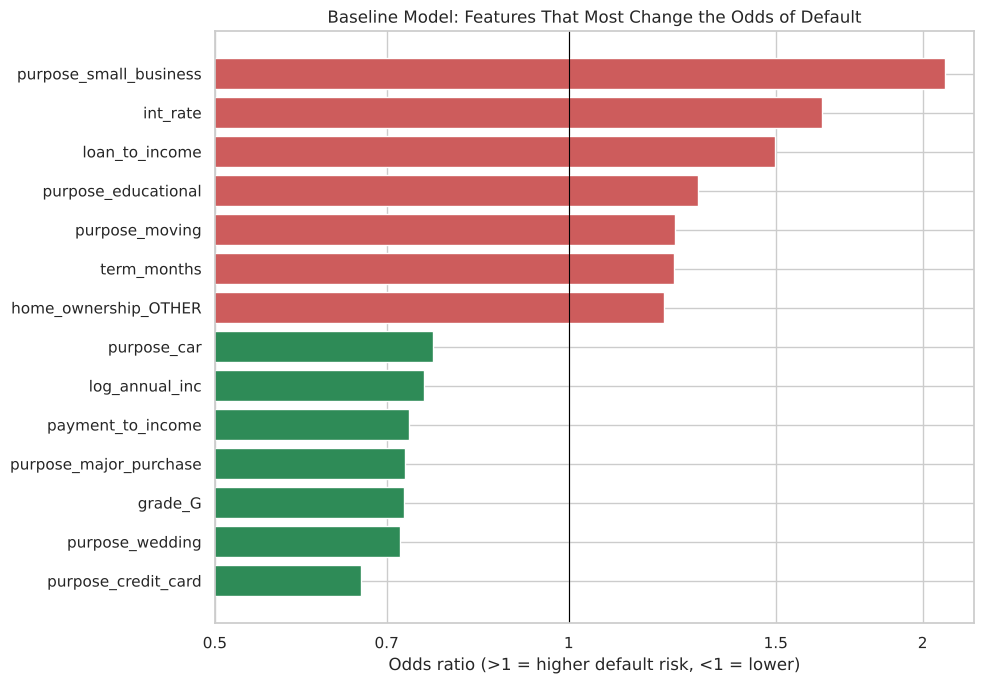

In [24]:
# Which features move the risk most? Odds ratios from the logistic regression
names = [n.split('__')[1] for n in baseline.named_steps['preprocess'].get_feature_names_out()]
odds = pd.Series(np.exp(baseline.named_steps['model'].coef_[0]), index=names).sort_values()
top = pd.concat([odds.head(7), odds.tail(7)])

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top.index, top.values, color=['seagreen' if v < 1 else 'indianred' for v in top.values])
ax.axvline(1, color='black', linewidth=0.8)
ax.set_xscale('log')
ticks = [0.5, 0.7, 1, 1.5, 2]
ax.set_xticks(ticks)
ax.set_xticklabels([str(v) for v in ticks])
ax.minorticks_off()
ax.set_title('Baseline Model: Features That Most Change the Odds of Default')
ax.set_xlabel('Odds ratio (>1 = higher default risk, <1 = lower)')
plt.tight_layout()
plt.savefig('../images/baseline_odds_ratios.png', dpi=100)
plt.show()

In [25]:
# What would the model do for a lender? Default rate among loans ranked riskiest by the model
ranked = pd.DataFrame({'prob': test_prob, 'default': y_test.values}).sort_values('prob', ascending=False)
deciles = pd.qcut(ranked['prob'].rank(method='first', ascending=False), 10, labels=range(1, 11))
ranked.groupby(deciles, observed=True)['default'].mean().mul(100).round(1).rename('default_rate_%').to_frame().T

prob,1,2,3,4,5,6,7,8,9,10
default_rate_%,36.5,25.6,19.1,15.5,11.7,12.6,10.0,8.0,4.5,2.6


**Interpreting the baseline**
- **ROC-AUC = 0.71** on the test set, and 0.709 ± 0.013 in 5-fold cross-validation. The model ranks borrowers clearly better than chance (0.5), and the close CV and test scores show it isn't overfitting.
- **It catches 64% of defaults (recall)**, while the naive "approve everyone" model catches none. The price is precision: only **25%** of the loans it flags actually default, and many good loans get flagged (2,734 in the test set). Accuracy drops to 66% because the model is deliberately cautious. That's expected, and it's why accuracy isn't the right metric here.
- **In practice the ranking is useful.** Loans the model places in its riskiest 10% default **36.5%** of the time, while loans in its safest 10% default only **2.6%** of the time. That's a 14× difference a lender could use to decide which applications get a closer review.
- **What raises risk (odds ratios):**
  - small business purpose (×2.1)
  - higher interest rate (×1.6 per standard deviation)
  - borrowing more relative to income (×1.5)
  - a 60-month term (×1.2)
  - higher income lowers risk (×0.75), as do credit card and car loans (×0.67–0.77)
- **Caution:** some coefficients look odd because features overlap. For example, `grade_G` gets an odds ratio below 1 even though G loans default the most, because interest rate already captures most of the grade effect. `payment_to_income` and `loan_to_income` overlap in the same way. These individual coefficients should be read as a group, not one by one.

## 8. Summary of findings and next steps

- After removing leakage columns and unfinished loans, **38,577 loans** remain, with a **14.6% default rate**.
- **The strongest warning signs** are a high interest rate / low grade, a 60-month term, a small business purpose, low income relative to the loan, and heavily used credit lines.
- **The baseline logistic regression reaches ROC-AUC 0.71 and catches 64% of defaults.** It separates the riskiest applicants (36.5% default) from the safest (2.6% default), which is already useful for deciding which applications need extra review.
- Precision is still low (25%), so the next stage should focus on ranking borrowers better and choosing a sensible cut-off.

**Next steps (Module 24)**
- **Try more models:** decision tree, random forest, gradient boosting and KNN. Compare them against this baseline on ROC-AUC, recall and precision.
- **Tune hyperparameters** with grid search and cross-validation.
- **Choose a decision threshold** that balances the cost of a missed default against the cost of reviewing a good loan, instead of the default 50% cut-off.
- **Reduce overlapping features** (for example, keep grade *or* interest rate, and one affordability ratio) to make the coefficients easier to explain.
- **Test on later loans** (for example, train on 2007–2010 and test on 2011) to see whether the model holds up over time.
- **Present the results** as simple rules and a risk-tier table that non-technical lending staff can use.